In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!gdown 1uUt7uL-VuF_5cpodYRiriEwhsldeEp3m

Downloading...
From: https://drive.google.com/uc?id=1uUt7uL-VuF_5cpodYRiriEwhsldeEp3m
To: /content/churn_logistic.csv
100% 494k/494k [00:00<00:00, 31.2MB/s]


In [ ]:
churn = pd.read_csv("churn_logistic.csv")
churn.head()

,Account Length,VMail Message,Day Mins,Eve Mins,Night Mins,Intl Mins,CustServ Calls,Intl Plan,VMail Plan,Day Calls,...,Eve Calls,Eve Charge,Night Calls,Night Charge,Intl Calls,Intl Charge,State,Area Code,Phone,Churn
0,128,25,265.1,197.4,244.7,10.0,1,0,1,110,...,99,16.78,91,11.01,3,2.70,KS,415,382-4657,0
1,107,26,161.6,195.5,254.4,13.7,1,0,1,123,...,103,16.62,103,11.45,3,3.70,OH,415,371-7191,0
2,137,0,243.4,121.2,162.6,12.2,0,0,0,114,...,110,10.30,104,7.32,5,3.29,NJ,415,358-1921,0
3,84,0,299.4,61.9,196.9,6.6,2,1,0,71,...,88,5.26,89,8.86,7,1.78,OH,408,375-9999,0
4,75,0,166.7,148.3,186.9,10.1,3,1,0,113,...,122,12.61,121,8.41,3,2.73,OK,415,330-6626,0


In [ ]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

In [ ]:
sigmoid(56)

1.0

In [ ]:
sigmoid(-54)

3.532628572200807e-24

In [ ]:
sigmoid(0)

0.5

In [ ]:
def log_loss(y, y_hat):
  return -np.mean(y*np.log(y_hat) + (1-y)*np.log(1-y_hat))

In [ ]:
log_loss(0, 0.00001)

1.0000050000287824e-05

In [ ]:
log_loss(0, 0.9999)

9.210340371976294

In [ ]:
log_loss(1, 0.99999)

1.0000050000287824e-05

In [ ]:
# logistic regression using sklearn

In [ ]:
cols = ['Day Mins', 'Eve Mins', 'Night Mins', 'CustServ Calls', 'Account Length']

y = churn["Churn"]
y = np.array(y).reshape(len(y), 1) #Reshaping our data to (m,1) shape
X = churn[cols]

X.shape

(5700, 5)

In [ ]:
from sklearn.model_selection import train_test_split

X_tr_cv, X_test, y_tr_cv, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_tr_cv, y_tr_cv, test_size=0.25,random_state=1)

X_train.shape

(3420, 5)

In [ ]:
X_val.head()

,Day Mins,Eve Mins,Night Mins,CustServ Calls,Account Length
3115,234.8,199.2,163.2,4,102
3094,133.8,158.8,189.6,1,91
5046,264.8,245.4,160.5,1,88
5661,122.3,118.8,147.9,3,131
5616,123.2,190.0,170.3,4,123


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = LogisticRegression()
model.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [ ]:
print("coef", model.coef_)
print("intercept", model.intercept_)

coef [[0.68445262 0.29104301 0.1363756  0.79630985 0.06125924]]
intercept [-0.01220319]


In [ ]:
y_pred = model.predict(X_val)
y_pred[:5]

array([1, 0, 1, 0, 1])

In [ ]:
model.score(X_val, y_val)

0.6982456140350877

In [ ]:
y_val = y_val.reshape(-1,)

In [ ]:
y_val

array([0, 0, 1, ..., 0, 1, 0])

In [ ]:
np.mean((y_pred == y_val)) # accuracy

0.6982456140350877

In [ ]:
y_train = y_train.reshape(-1, )
y_test = y_test.reshape(-1, )

In [ ]:
from sklearn.pipeline import make_pipeline

train_scores = []
val_scores = []

for lam in np.arange(0.01, 5000.0, 100): # range of values of Lambda
  scaled_lr = make_pipeline(StandardScaler(), LogisticRegression(C=1/lam))
  scaled_lr.fit(X_train, y_train)

  train_score = scaled_lr.score(X_train, y_train)
  val_score = scaled_lr.score(X_val, y_val)

  train_scores.append(train_score)
  val_scores.append(val_score)

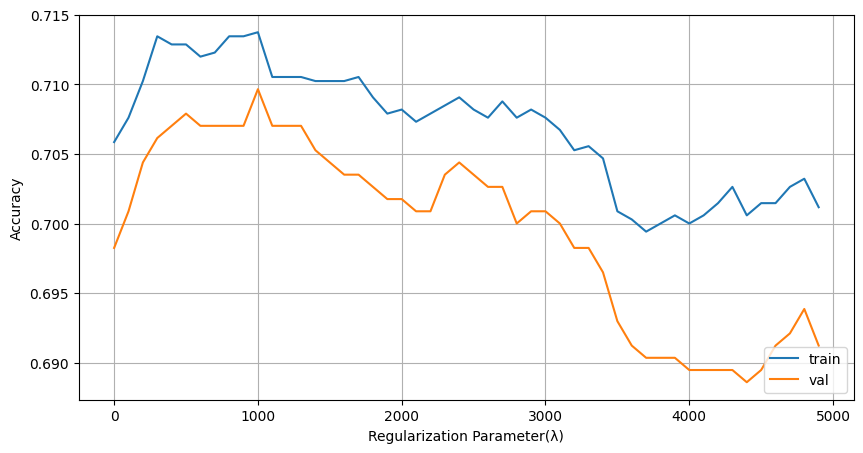

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(0.01, 5000.0, 100)), train_scores, label="train")
plt.plot(list(np.arange(0.01, 5000.0, 100)), val_scores, label="val")
plt.legend(loc='lower right')

plt.xlabel("Regularization Parameter(λ)")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
model = LogisticRegression(C=1/1000)
model.fit(X_train, y_train)

print("Train acc = ",model.score(X_train, y_train))


print("Val acc = ",model.score(X_val, y_val))

Train acc =  0.7137426900584796
Val acc =  0.7096491228070175


In [ ]:
model.score(X_test, y_test)

0.7096491228070175

In [ ]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples= 500,
                           n_features= 2,
                           n_classes = 3,
                           n_redundant=0,
                           n_clusters_per_class=1,
                           random_state=5)

In [ ]:
X.shape, y.shape

((500, 2), (500,))

In [ ]:
y[:5]

array([1, 0, 1, 1, 2])

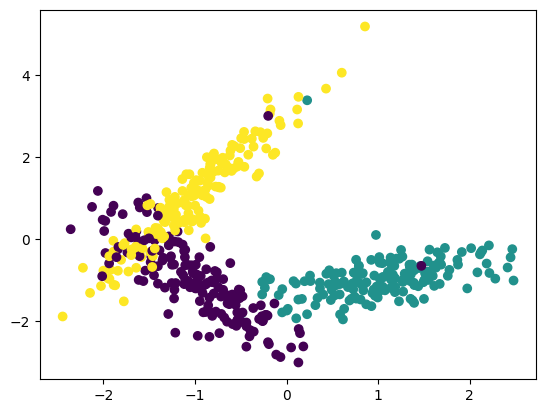

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c = y)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_tr_cv, X_test, y_tr_cv, y_test = train_test_split(X, y, test_size=0.2, random_state=4)
X_train, X_val, y_train, y_val = train_test_split(X_tr_cv, y_tr_cv, test_size=0.25,random_state=4)
X_train.shape

(300, 2)

In [ ]:
model = LogisticRegression(multi_class='ovr')
model.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(multi_class='ovr')

In [ ]:
print(f'Training Accuracy:{model.score(X_train,y_train)}')
print(f'Validation Accuracy :{model.score(X_val,y_val)}')

Training Accuracy:0.8633333333333333
Validation Accuracy :0.88


In [ ]:
model.predict(X_val)

array([1, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 1, 2, 1, 0, 1, 0, 2, 1, 1, 2, 1,
       0, 0, 1, 2, 0, 2, 0, 1, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 2, 0, 0, 0, 2, 2, 0, 0, 1, 2, 0, 1, 1, 0, 2, 2, 2, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 0, 2, 0, 0, 0, 2, 1, 0, 2, 1, 0, 2, 2, 0,
       1, 2, 1, 0, 1, 1, 0, 2, 1, 2, 1, 0])

In [ ]:
model.predict_proba(X_val).round(2)[:5]

array([[0.01, 0.97, 0.01],
       [0.08, 0.  , 0.92],
       [0.87, 0.07, 0.06],
       [0.67, 0.03, 0.3 ],
       [0.06, 0.01, 0.93]])

<ipython-input-41-0eed0f32ddf7>:11: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


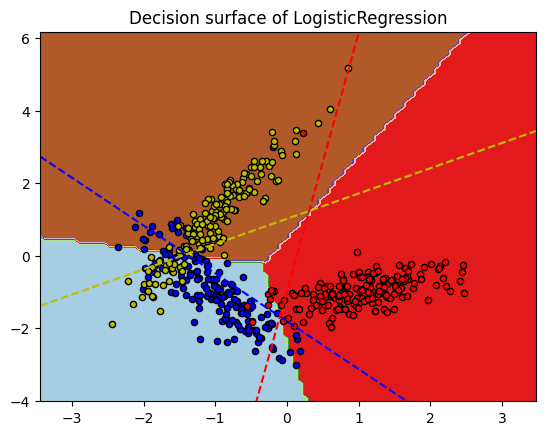

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay
_, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict", cmap=plt.cm.Paired, ax=ax)
plt.title("Decision surface of LogisticRegression")
plt.axis("tight")

# Plot also the training points
colors = "bry"
for i, color in zip(model.classes_, colors):
        idx = np.where(y == i)
        plt.scatter(
            X[idx, 0], X[idx, 1], c=color, cmap=plt.cm.Paired, edgecolor="black", s=20
        )


# Plot the three one-against-all classifiers
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()
coef = model.coef_
intercept = model.intercept_

def plot_hyperplane(c, color):
        def line(x0):
            return (-(x0 * coef[c, 0]) - intercept[c]) / coef[c, 1]

        plt.plot([xmin, xmax], [line(xmin), line(xmax)], ls="--", color=color)

for i, color in zip(model.classes_, colors):
        plot_hyperplane(i, color)

plt.show()